<a href="https://colab.research.google.com/github/Roshan-Bhadane/ML_LABS/blob/main/ML_PR_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name: Roshan Chandrakant Bhadane
*   Div: CSE-A
*   Practical Batch: A-1
*   Roll No: 01
*   Date: 21/10/2026
*   Practical No: 7
*   Practical Name: Implement K-Means clustering. Find the optimal number of clusters using the Elbow method and Silhouette score.

## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (6, 5)
plt.rcParams['figure.dpi'] = 100
sns.set_style('darkgrid')

## 2. Load Dataset

In [ ]:
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Exploratory Data Analysis (EDA)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
data = df[features]
data.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


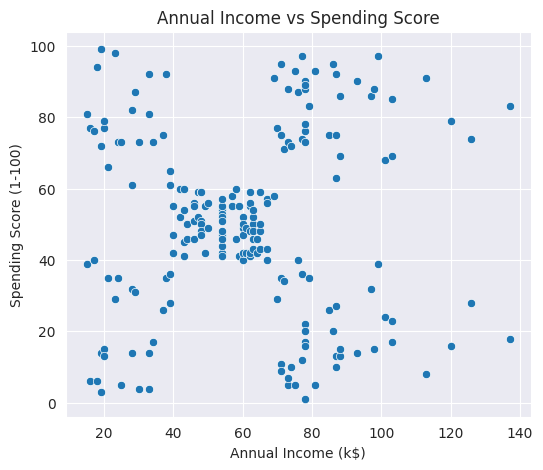

In [ ]:
sns.scatterplot(x=data['Annual Income (k$)'], y=data['Spending Score (1-100)'])
plt.title("Annual Income vs Spending Score")
plt.show()

## 4. Data Preprocessing

K-Means uses distances, so both features are standardised to mean 0 and standard deviation 1.

In [ ]:
sc = StandardScaler()
x = sc.fit_transform(data)
x[:10]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

## 5. K-Means with Default Clusters (K = 8)

In [ ]:
km = KMeans(n_clusters=8, random_state=42, n_init=10)
yp = km.fit_predict(x)
yp

array([4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5,
       4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 2, 2,
       4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 6, 1, 6, 3, 6, 3, 6,
       1, 6, 3, 6, 3, 6, 3, 6, 3, 6, 1, 6, 3, 6, 1, 6, 3, 6, 3, 6, 3, 6,
       3, 6, 3, 6, 3, 6, 1, 6, 3, 6, 3, 6, 3, 6, 3, 6, 3, 6, 3, 6, 3, 6,
       3, 6, 3, 0, 7, 0, 7, 0, 7, 0, 7, 0, 7, 0, 7, 0, 7, 0, 7, 0, 7, 0,
       7, 0], dtype=int32)

In [ ]:
len(yp)

200

In [ ]:
# cluster centres (standardised scale)
km.cluster_centers_

array([[ 1.81769762,  1.26275949],
       [ 0.1206509 , -0.15673077],
       [-0.49804891,  0.06175337],
       [ 0.7489536 , -1.45651437],
       [-1.32954532, -1.16358805],
       [-1.35366972,  1.15873115],
       [ 0.66703804,  1.23036618],
       [ 1.87564575, -1.09476801]])

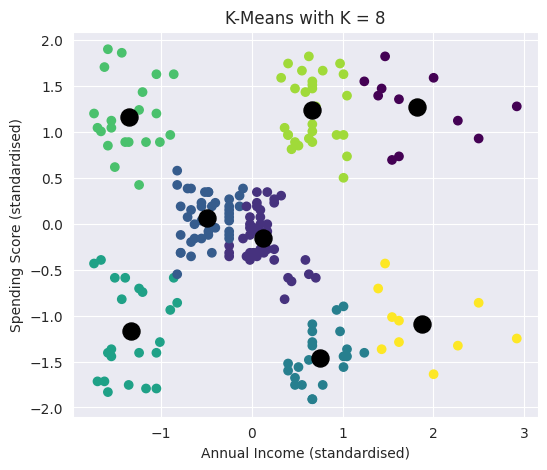

In [ ]:
plt.scatter(x[:, 0], x[:, 1], c=yp, cmap='viridis')
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='black', s=150)
plt.xlabel("Annual Income (standardised)")
plt.ylabel("Spending Score (standardised)")
plt.title("K-Means with K = 8")
plt.show()

In [ ]:
# inertia = sum of squared distances of each sample to its nearest centre
km.inertia_

37.22818767758587

In [ ]:
silhouette_score(x, yp)

np.float64(0.4552147906587443)

## 6. Elbow Method

The elbow curve is the plot of K against WCSS (Within-Cluster Sum of Squares).

In [ ]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(x)
    wcss.append(model.inertia_)

wcss

[399.99999999999994,
 269.69101219276405,
 157.70400815035939,
 108.92131661364358,
 65.56840815571681,
 55.057348270385965,
 44.86475569922555,
 37.22818767758587,
 32.39226763033118,
 29.981897788243703]

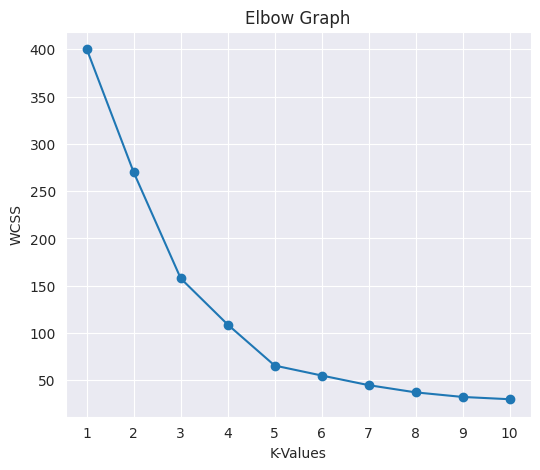

In [ ]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('K-Values')
plt.ylabel('WCSS')
plt.title('Elbow Graph')
plt.xticks(range(1, 11))
plt.show()

## 7. Silhouette Score Analysis

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x)
    score = silhouette_score(x, labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


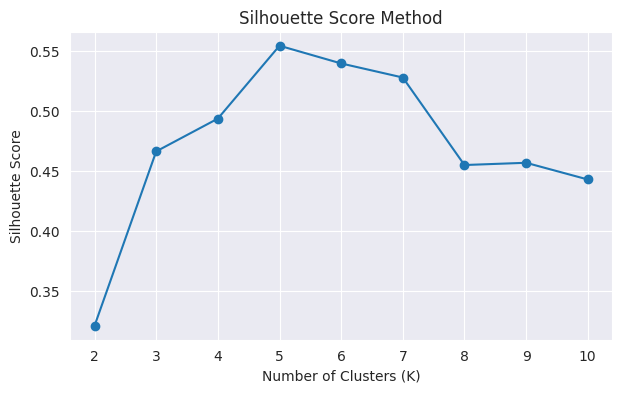

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.show()

In [ ]:
best_k = range(2, 11)[int(np.argmax(silhouette_scores))]
print("Optimal K (highest silhouette score):", best_k)

Optimal K (highest silhouette score): 5


## 8. Final K-Means Model

In [ ]:
final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = final_km.fit_predict(x)

print("Silhouette Score:", silhouette_score(x, df['Cluster']))
print("Inertia:", final_km.inertia_)

Silhouette Score: 0.5546571631111091
Inertia: 65.56840815571681


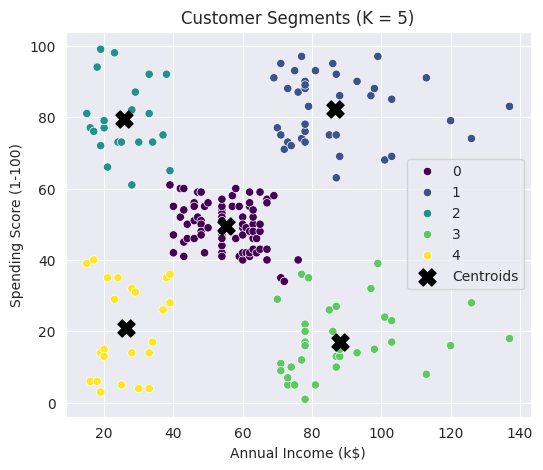

In [ ]:
centers = sc.inverse_transform(final_km.cluster_centers_)

sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'],
                hue=df['Cluster'], palette='viridis')
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=150, marker='X', label='Centroids')
plt.title(f"Customer Segments (K = {best_k})")
plt.legend()
plt.show()

In [ ]:
print("Customers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [ ]:
df.groupby('Cluster')[features].mean().round(1)

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


## 9. Predict Cluster for New Customers

In [ ]:
new_customers = pd.DataFrame([[20, 90], [120, 15]], columns=features)

new_clusters = final_km.predict(sc.transform(new_customers))

for (income, score), c in zip(new_customers.values, new_clusters):
    print(f"Income = {income}k$, Spending Score = {score}  ->  Cluster {c}")

Income = 20k$, Spending Score = 90  ->  Cluster 2
Income = 120k$, Spending Score = 15  ->  Cluster 3


## 10. Conclusion

*   K-Means was applied to the Annual Income and Spending Score of mall customers after standardising the features.
*   The Elbow curve flattens after the optimal K, and the Silhouette score is highest at the best K, so both methods are used to choose the number of clusters.
*   The final model groups customers into segments that can be used for targeted marketing, such as high-income high-spending customers versus low-income high-spending customers.